# Controlled Comparison: RL then SFT vs Direct Additional SFT

This notebook runs a matched additional-SFT experiment using your saved adapters:

- **Route A:** original SFT -> **existing saved RL model** -> additional SFT.
- **Route B:** original SFT -> the **same additional SFT** directly.

Both branches use the same 64 new supervised training questions, original GSM8K reference solutions, one epoch, learning rate 1e-5, data order, batching, and seed. No teacher generation is required. The saved RL model is reused, not retrained. Defaults use GRPO; switch RL_STAGE to dapo to use your saved DAPO model.

All four models (original SFT, original RL, Route A, Route B) are evaluated on the same **64 fresh GSM8K test questions**, excluding question text found in your saved original splits and external-evaluation subsets. This notebook does not select training examples using test errors. Deduplication is exact normalized matching only; semantic and pretraining overlap are unknown.

The appended SFT budget is matched. Total pipeline compute is **not** matched because Route A already includes earlier RL. This experiment asks whether the saved RL stage adds value after the same additional supervision, not whether RL beats an equally costly SFT-only pipeline.

No original adapters, datasets, or evaluation files are overwritten. A new experiment folder stores all new artifacts. This is a single-seed, small-scale experiment; do not treat a one-question difference as a stable gain.


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, json, time, subprocess
from pathlib import Path

PROJECT = Path('/content/drive/MyDrive/qwen3_1p7b_128_en')
ROOT = PROJECT/'runs'/'ds8b_qwen1p7b_128_001'
RL_STAGE = 'grpo'  # 'grpo' or 'dapo'
DAPO_RUN = 'dapo_001'
NAME = f'matched_{RL_STAGE}_post_sft_001'
TRAIN_N, TEST_N = 64, 64
EPOCHS = 1
LEARNING_RATE = 1e-5
SEQ_LEN, EVAL_TOKENS = 2048, 2048
SEED = 42
STUDENT_CACHE = Path('/content/qwen1p7b_student_cache')

assert RL_STAGE in {'grpo', 'dapo'}
SFT_SOURCE = ROOT/'sft'/'final'
RL_SOURCE = ROOT/'grpo'/'final' if RL_STAGE == 'grpo' else ROOT/'dapo'/DAPO_RUN/'final'
OUT = ROOT/'post_sft_comparison'/NAME
required = [PROJECT/'pipeline.py', PROJECT/'monitoring.py', PROJECT/'requirements.txt', ROOT/'manifest.json']
for path in [SFT_SOURCE, RL_SOURCE]:
    required += [path/'adapter_config.json', path/'adapter_model.safetensors']
missing = [str(p) for p in required if not p.exists()]
assert not missing, 'Missing saved project/model files:\n'+'\n'.join(missing)
os.chdir(PROJECT)
print('Route A starts from:', RL_SOURCE)
print('Route B starts from:', SFT_SOURCE)
print('New artifacts:', OUT)


Mounted at /content/drive
Route A starts from: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/grpo/final
Route B starts from: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/sft/final
New artifacts: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/post_sft_comparison/matched_grpo_post_sft_001


## Dependencies

Use the original project environment. The optional compatibility repair removes unused Gradio/Diffusers if the known Colab dependency conflicts occur; it does not delete saved models or model caches. If Colab requests a restart, restart the session and rerun from the first cell. No original training notebook needs to be running.


In [2]:
def stream_command(command, env=None, logfile=None):
    print('Running:', ' '.join(map(str, command)), flush=True)
    handle = open(logfile, 'a', encoding='utf-8') if logfile else None
    proc = subprocess.Popen(list(map(str, command)), cwd=PROJECT, env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    try:
        for line in proc.stdout:
            print(line, end='', flush=True)
            if handle:
                handle.write(line)
                handle.flush()
        code = proc.wait()
        if code:
            raise RuntimeError(f'Command failed with exit code {code}. Read the output above. Log: {logfile}')
    except BaseException:
        if proc.poll() is None:
            proc.terminate()
            try:
                proc.wait(timeout=20)
            except subprocess.TimeoutExpired:
                proc.kill()
                proc.wait()
        raise
    finally:
        if handle:
            handle.close()

REPAIR_KNOWN_COLAB_CONFLICTS = True
stream_command([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT/'requirements.txt')])
check = subprocess.run([sys.executable, '-m', 'pip', 'check'],
                       capture_output=True, text=True)
print(check.stdout, check.stderr)
if check.returncode:
    repair = PROJECT/'repair_colab.py'
    if REPAIR_KNOWN_COLAB_CONFLICTS and repair.exists():
        stream_command([sys.executable, '-u', str(repair)])
    else:
        raise RuntimeError('Dependency conflicts remain. Inspect pip check output before proceeding.')
stream_command([sys.executable, '-m', 'pip', 'check'])
stream_command([sys.executable, '-c',
    'import importlib.metadata as m; from transformers import Trainer; from peft import PeftModel; '
    'from trl import GRPOTrainer; assert m.version("trl")=="0.23.1"; print("Training imports OK")'])


Running: /usr/bin/python3 -m pip install -r /content/drive/MyDrive/qwen3_1p7b_128_en/requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 90.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 564.6/564.6 kB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 503.6/503.6 kB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━

In [3]:
stream_command(['nvidia-smi'])
import torch
assert torch.cuda.is_available(), 'Select a GPU runtime.'
assert torch.cuda.is_bf16_supported(), 'The existing loader requires BF16 support.'
print('GPU:', torch.cuda.get_device_name())
print('VRAM GiB:', round(torch.cuda.get_device_properties(0).total_memory/2**30, 2))


Running: nvidia-smi
Mon Oct 19 05:27:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------

## Embed the experiment runner

Only this notebook needs to be uploaded separately. The script is embedded and written to a temporary Colab directory. The original project modules remain on Drive. New checkpoints, logs, and results are persisted to Drive.


In [4]:
EXPERIMENT_SOURCE = '"""Compare saved SFT -> saved RL -> additional SFT vs SFT -> additional SFT.\n\nBoth branches use exactly the same fresh supervised examples and update settings.\nExisting adapters remain unchanged. RL is reused, not rerun.\n"""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport math\nimport random\nimport re\nimport time\nfrom pathlib import Path\n\nfrom pipeline import STUDENT, prompt, read, write, uid, normalize, numeric, extract, correct, load_model, meta\nfrom monitoring import Progress, training_callback\n\n\ndef sha(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for chunk in iter(lambda: f.read(1024*1024), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef supervised_answer(reference):\n    if \'####\' not in reference:\n        raise ValueError(\'GSM8K reference is missing its final answer.\')\n    reasoning, gold = reference.rsplit(\'####\', 1)\n    gold = gold.strip()\n    if numeric(gold) is None:\n        raise ValueError(\'Unparseable reference answer.\')\n    reasoning = re.sub(r\'<<.*?>>\', \'\', reasoning).strip()\n    return reasoning+\'\\n#### \'+gold, gold\n\n\ndef unique_unseen(raw, forbidden, seed):\n    rows, seen = [], set(forbidden)\n    for row in raw:\n        key = normalize(row[\'question\'])\n        if key in seen:\n            continue\n        seen.add(key)\n        completion, gold = supervised_answer(row[\'answer\'])\n        rows.append({\'id\': uid(row[\'question\']), \'question\': row[\'question\'],\n                     \'answer\': gold, \'reference_completion\': completion})\n    random.Random(seed).shuffle(rows)\n    return rows\n\n\ndef locations(a):\n    sft = a.root/\'sft\'/\'final\'\n    rl = a.root/\'grpo\'/\'final\' if a.rl_stage == \'grpo\' else a.root/\'dapo\'/a.dapo_run/\'final\'\n    out = a.root/\'post_sft_comparison\'/a.name\n    return sft, rl, out\n\n\ndef fingerprint_adapter(folder):\n    return {name: sha(folder/name) for name in [\'adapter_config.json\', \'adapter_model.safetensors\']}\n\n\ndef experiment_settings(a):\n    sft, rl, out = locations(a)\n    provenance = {}\n    paths = list((a.root/\'data\').glob(\'*.jsonl\'))\n    paths += list((a.root/\'external_eval\').glob(\'**/questions.jsonl\'))\n    for path in sorted(paths):\n        if path.name in {\'teacher_attempts.jsonl\', \'sft.jsonl\'}:\n            continue\n        provenance[str(path.relative_to(a.root))] = sha(path)\n    return {\'sft_source\': str(sft), \'rl_source\': str(rl), \'rl_stage\': a.rl_stage,\n            \'sft_adapter\': fingerprint_adapter(sft), \'rl_adapter\': fingerprint_adapter(rl),\n            \'original_manifest_sha256\': sha(a.root/\'manifest.json\'),\n            \'seen_question_files\': provenance, \'train_n\': a.train_n, \'test_n\': a.test_n,\n            \'seq_len\': a.seq_len, \'eval_tokens\': a.eval_tokens, \'epochs\': a.epochs,\n            \'learning_rate\': a.learning_rate, \'seed\': a.seed, \'gradient_accumulation\': 8,\n            \'microbatch\': 1, \'supervision\': \'GSM8K original train reference solutions\',\n            \'code_sha256\': sha(__file__), \'pipeline_sha256\': sha(__import__(\'pipeline\').__file__)}\n\n\ndef prepare(a, out):\n    from datasets import load_dataset\n    from transformers import AutoTokenizer\n    current = experiment_settings(a)\n    plan = out/\'experiment.json\'\n    if plan.exists():\n        old = json.loads(plan.read_text())\n        if old[\'settings\'] != current:\n            raise ValueError(\'Source adapters/data/code or experiment settings changed. Use a new --name.\')\n        for name, expected in old[\'files\'].items():\n            if sha(out/name) != expected:\n                raise ValueError(f\'Frozen file changed: {name}\')\n        print(\'[prepare] Reusing frozen matched training/evaluation data.\', flush=True)\n        return\n    forbidden = set()\n    for path in current[\'seen_question_files\']:\n        for r in read(a.root/path):\n            if \'question\' in r:\n                forbidden.add(normalize(r[\'question\']))\n    revision = meta(a.root)[\'dataset_revisions\'][\'openai/gsm8k\']\n    train = load_dataset(\'openai/gsm8k\', \'main\', split=\'train\', revision=revision)\n    test = load_dataset(\'openai/gsm8k\', \'main\', split=\'test\', revision=revision)\n    train_pool = unique_unseen(train, forbidden, a.seed)\n    tok = AutoTokenizer.from_pretrained(STUDENT, revision=meta(a.root)[\'model_revisions\'][STUDENT])\n    selected, examples = [], []\n    for r in train_pool:\n        p = tok(prompt(r[\'question\']), add_special_tokens=False).input_ids\n        c = tok(r[\'reference_completion\']+tok.eos_token, add_special_tokens=False).input_ids\n        if len(p)+len(c) > a.seq_len:\n            continue\n        selected.append(r)\n        examples.append({\'id\': r[\'id\'], \'input_ids\': p+c, \'labels\': [-100]*len(p)+c})\n        if len(selected) == a.train_n:\n            break\n    if len(selected) < a.train_n:\n        raise ValueError(\'Not enough unseen complete supervised examples fit the sequence limit.\')\n    forbidden.update(normalize(r[\'question\']) for r in selected)\n    tests = unique_unseen(test, forbidden, a.seed)\n    if len(tests) < a.test_n:\n        raise ValueError(\'Not enough fresh test questions remain.\')\n    # Test reference solutions are deliberately not saved or passed to inference.\n    tests = [{k: r[k] for k in [\'id\', \'question\', \'answer\']} for r in tests[:a.test_n]]\n    files = {\'additional_train.jsonl\': selected, \'tokenized_train.jsonl\': examples,\n             \'fresh_test.jsonl\': tests}\n    for name, rows in files.items():\n        write(out/name, rows)\n    plan.write_text(json.dumps({\'settings\': current, \'files\': {name: sha(out/name) for name in files},\n                                \'dataset_revision\': revision,\n                                \'limitations\': \'Exact question deduplication only; unknown semantic/pretraining overlap.\'},\n                               indent=2), encoding=\'utf-8\')\n    print(f\'[prepare] Frozen {len(selected)} new supervised examples and {len(tests)} fresh test questions.\', flush=True)\n\n\ndef train(a, out):\n    import torch\n    from datasets import Dataset\n    from transformers import Trainer, TrainingArguments, set_seed\n    set_seed(a.seed)\n    source_sft, source_rl, _ = locations(a)\n    source = source_rl if a.branch == \'rl_then_sft\' else source_sft\n    dest = out/a.branch\n    if (dest/\'COMPLETE.json\').exists():\n        print(f\'[train] {a.branch} already complete; keeping the saved adapter.\', flush=True)\n        return\n    examples = read(out/\'tokenized_train.jsonl\')\n    model, tok = load_model(STUDENT, a.root, adapter=source, train=True)\n    model.config.use_cache = False\n    model.enable_input_require_grads()\n    model.print_trainable_parameters()\n    def collate(batch):\n        n = max(len(x[\'input_ids\']) for x in batch)\n        return {\'input_ids\': torch.tensor([x[\'input_ids\']+[tok.pad_token_id]*(n-len(x[\'input_ids\'])) for x in batch]),\n                \'attention_mask\': torch.tensor([[1]*len(x[\'input_ids\'])+[0]*(n-len(x[\'input_ids\'])) for x in batch]),\n                \'labels\': torch.tensor([x[\'labels\']+[-100]*(n-len(x[\'labels\'])) for x in batch])}\n    config = TrainingArguments(output_dir=str(dest/\'checkpoints\'),\n                               per_device_train_batch_size=1, gradient_accumulation_steps=8,\n                               num_train_epochs=a.epochs, learning_rate=a.learning_rate,\n                               bf16=True, gradient_checkpointing=True,\n                               gradient_checkpointing_kwargs={\'use_reentrant\': False},\n                               logging_steps=1, save_steps=4, save_total_limit=2,\n                               disable_tqdm=True, report_to=\'none\', seed=a.seed, data_seed=a.seed)\n    trainer = Trainer(model=model, args=config, train_dataset=Dataset.from_list(examples),\n                      data_collator=collate, processing_class=tok,\n                      callbacks=[training_callback(dest, a.branch)])\n    checkpoints = sorted((dest/\'checkpoints\').glob(\'checkpoint-*\'),\n                         key=lambda p: int(p.name.split(\'-\')[-1]))\n    print(f\'[train] branch={a.branch}; start={source}; examples={len(examples)}; \'\n          f\'epochs={a.epochs}; learning_rate={a.learning_rate}\', flush=True)\n    start = time.perf_counter()\n    result = trainer.train(resume_from_checkpoint=str(checkpoints[-1]) if checkpoints else None)\n    trainer.save_model(str(dest/\'final\'))\n    tok.save_pretrained(dest/\'final\')\n    (dest/\'COMPLETE.json\').write_text(json.dumps({\'global_step\': trainer.state.global_step,\n        \'session_seconds\': time.perf_counter()-start, \'resumed\': bool(checkpoints),\n        \'source_adapter\': str(source), \'training_metrics\': result.metrics}, indent=2), encoding=\'utf-8\')\n\n\ndef summarize(rows, stage, budget):\n    n = len(rows)\n    if not n:\n        raise ValueError(\'Empty evaluation.\')\n    corrects = sum(correct(r[\'text\'], r[\'answer\']) for r in rows)\n    parsed = [extract(r[\'text\']) for r in rows]\n    return {\'stage\': stage, \'n\': n, \'correct\': corrects, \'accuracy_percent\': 100*corrects/n,\n            \'answer_parse_percent\': 100*sum(x is not None and numeric(x) is not None for x in parsed)/n,\n            \'mean_tokens\': sum(r[\'tokens\'] for r in rows)/n,\n            \'mean_seconds\': sum(r[\'seconds\'] for r in rows)/n,\n            \'budget_hit_percent\': 100*sum(r[\'budget_hit\'] for r in rows)/n, \'eval_budget\': budget}\n\n\ndef evaluate(a, out):\n    import torch\n    from transformers import set_seed\n    set_seed(a.seed)\n    original_sft, original_rl, _ = locations(a)\n    source = {\'original_sft\': original_sft, \'original_rl\': original_rl,\n              \'rl_then_sft\': out/\'rl_then_sft\'/\'final\', \'direct_sft\': out/\'direct_sft\'/\'final\'}[a.stage]\n    if a.stage in {\'rl_then_sft\', \'direct_sft\'} and not (out/a.stage/\'COMPLETE.json\').exists():\n        raise ValueError(f\'Train {a.stage} before evaluation.\')\n    questions = read(out/\'fresh_test.jsonl\')\n    ev = out/\'eval\'\n    ev.mkdir(exist_ok=True)\n    file = ev/f\'{a.stage}.predictions.jsonl\'\n    config_file = ev/f\'{a.stage}.settings.json\'\n    config = {\'adapter\': fingerprint_adapter(source), \'test_sha256\': sha(out/\'fresh_test.jsonl\'),\n              \'budget\': a.eval_tokens, \'decoding\': \'greedy\', \'seed\': a.seed}\n    if config_file.exists() and json.loads(config_file.read_text()) != config:\n        raise ValueError(\'Evaluation inputs changed; use a new experiment name.\')\n    config_file.write_text(json.dumps(config, indent=2), encoding=\'utf-8\')\n    rows = read(file) if file.exists() else []\n    expected = {q[\'id\']: (q[\'question\'], q[\'answer\']) for q in questions}\n    if len({r[\'id\'] for r in rows}) != len(rows) or any(\n            expected.get(r[\'id\']) != (r[\'question\'], r[\'answer\']) for r in rows):\n        raise ValueError(\'Saved predictions do not match the frozen test set.\')\n    done = {r[\'id\'] for r in rows}\n    progress = Progress(out, \'eval_\'+a.stage, len(questions), initial=len(done))\n    progress.update(len(done))\n    if len(done) < len(questions):\n        model, tok = load_model(STUDENT, a.root, adapter=source)\n        model.eval()\n        with file.open(\'a\', encoding=\'utf-8\') as f:\n            for q in questions:\n                if q[\'id\'] in done:\n                    continue\n                inputs = tok(prompt(q[\'question\']), add_special_tokens=False, return_tensors=\'pt\').to(model.device)\n                torch.cuda.synchronize()\n                start = time.perf_counter()\n                with torch.inference_mode():\n                    ids = model.generate(**inputs, do_sample=False, max_new_tokens=a.eval_tokens,\n                                         eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)\n                torch.cuda.synchronize()\n                new = ids[0, inputs.input_ids.shape[1]:]\n                text = tok.decode(new, skip_special_tokens=True)\n                row = {**q, \'text\': text, \'correct\': correct(text, q[\'answer\']), \'tokens\': len(new),\n                       \'seconds\': time.perf_counter()-start,\n                       \'budget_hit\': len(new) >= a.eval_tokens and int(new[-1]) != tok.eos_token_id}\n                f.write(json.dumps(row, ensure_ascii=False)+\'\\n\')\n                f.flush()\n                rows.append(row)\n                done.add(q[\'id\'])\n                progress.update(len(done), correct=row[\'correct\'], tokens=row[\'tokens\'])\n    summary = summarize(rows, a.stage, a.eval_tokens)\n    (ev/f\'{a.stage}.summary.json\').write_text(json.dumps(summary, indent=2), encoding=\'utf-8\')\n    print(json.dumps(summary, indent=2))\n\n\ndef paired_comparison(left, right):\n    a = {r[\'id\']: correct(r[\'text\'], r[\'answer\']) for r in left}\n    b = {r[\'id\']: correct(r[\'text\'], r[\'answer\']) for r in right}\n    if set(a) != set(b):\n        raise ValueError(\'Paired evaluation needs identical test IDs.\')\n    return {\'rl_then_sft_only_correct\': sum(a[k] and not b[k] for k in a),\n            \'direct_sft_only_correct\': sum(b[k] and not a[k] for k in a),\n            \'both_correct\': sum(a[k] and b[k] for k in a),\n            \'both_wrong\': sum(not a[k] and not b[k] for k in a)}\n\n\ndef report(a, out):\n    rows = [json.loads(p.read_text()) for stage in [\'original_sft\', \'original_rl\', \'rl_then_sft\', \'direct_sft\']\n            if (p := out/\'eval\'/f\'{stage}.summary.json\').exists()]\n    if not rows:\n        print(\'No completed evaluations yet.\')\n        return\n    with (out/\'comparison.csv\').open(\'w\', newline=\'\', encoding=\'utf-8\') as f:\n        writer = csv.DictWriter(f, fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n    left, right = out/\'eval/rl_then_sft.predictions.jsonl\', out/\'eval/direct_sft.predictions.jsonl\'\n    if left.exists() and right.exists():\n        paired = paired_comparison(read(left), read(right))\n        (out/\'paired_comparison.json\').write_text(json.dumps(paired, indent=2), encoding=\'utf-8\')\n        print(\'Paired comparison:\', json.dumps(paired))\n    print(\'Results:\', json.dumps(rows, indent=2))\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'command\', choices=[\'prepare\', \'train\', \'eval\', \'report\'])\n    p.add_argument(\'--root\', type=Path, required=True)\n    p.add_argument(\'--name\', default=\'matched_post_sft_001\')\n    p.add_argument(\'--rl-stage\', choices=[\'grpo\', \'dapo\'], default=\'grpo\')\n    p.add_argument(\'--dapo-run\', default=\'dapo_001\')\n    p.add_argument(\'--train-n\', type=int, default=64)\n    p.add_argument(\'--test-n\', type=int, default=64)\n    p.add_argument(\'--seq-len\', type=int, default=2048)\n    p.add_argument(\'--eval-tokens\', type=int, default=2048)\n    p.add_argument(\'--learning-rate\', type=float, default=1e-5)\n    p.add_argument(\'--epochs\', type=int, default=1)\n    p.add_argument(\'--seed\', type=int, default=42)\n    p.add_argument(\'--branch\', choices=[\'rl_then_sft\', \'direct_sft\'], default=\'rl_then_sft\')\n    p.add_argument(\'--stage\', choices=[\'original_sft\', \'original_rl\', \'rl_then_sft\', \'direct_sft\'], default=\'original_sft\')\n    a = p.parse_args()\n    if min(a.train_n, a.test_n, a.epochs, a.seq_len, a.eval_tokens) < 1 or a.learning_rate <= 0:\n        p.error(\'Dataset sizes, epochs, sequence budgets, and learning rate must be positive.\')\n    for name in [a.name, a.dapo_run]:\n        if not name or Path(name).name != name or name in {\'.\', \'..\'}:\n            p.error(\'Use simple directory names.\')\n    sft, rl, out = locations(a)\n    left = json.loads((sft/\'adapter_config.json\').read_text())\n    right = json.loads((rl/\'adapter_config.json\').read_text())\n    for field in [\'r\', \'lora_alpha\', \'lora_dropout\', \'target_modules\']:\n        v, w = left.get(field), right.get(field)\n        if field == \'target_modules\' and isinstance(v, list) and isinstance(w, list):\n            v, w = sorted(v), sorted(w)\n        if v != w:\n            p.error(f\'LoRA configurations differ at {field}; this would confound the comparison.\')\n    out.mkdir(parents=True, exist_ok=True)\n    prepare(a, out)\n    if a.command == \'train\':\n        train(a, out)\n    elif a.command == \'eval\':\n        evaluate(a, out)\n    elif a.command == \'report\':\n        report(a, out)\n\n\nif __name__ == \'__main__\':\n    main()\n'
SCRIPT_DIR = Path('/content/post_sft_comparison_runner')
SCRIPT_DIR.mkdir(parents=True, exist_ok=True)
SCRIPT = SCRIPT_DIR/'compare_post_sft.py'
compile(EXPERIMENT_SOURCE, str(SCRIPT), 'exec')
SCRIPT.write_text(EXPERIMENT_SOURCE, encoding='utf-8')
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'console_logs').mkdir(exist_ok=True)
env = dict(os.environ)
env['HF_HOME'] = str(STUDENT_CACHE)
env['PYTHONPATH'] = str(PROJECT)+os.pathsep+env.get('PYTHONPATH', '')
env['TOKENIZERS_PARALLELISM'] = 'false'
env['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
env['PYTHONUNBUFFERED'] = '1'

def experiment(command, *extra):
    args = [sys.executable, '-u', str(SCRIPT), command, '--root', str(ROOT), '--name', NAME,
            '--rl-stage', RL_STAGE, '--dapo-run', DAPO_RUN, '--train-n', str(TRAIN_N),
            '--test-n', str(TEST_N), '--epochs', str(EPOCHS), '--learning-rate', str(LEARNING_RATE),
            '--seq-len', str(SEQ_LEN), '--eval-tokens', str(EVAL_TOKENS), '--seed', str(SEED),
            *map(str, extra)]
    log = OUT/'console_logs'/f'{command}_{time.time_ns()}.log'
    stream_command(args, env=env, logfile=log)

freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
(OUT/'environment.txt').write_text(freeze, encoding='utf-8')
(OUT/'hardware.json').write_text(json.dumps({'gpu':torch.cuda.get_device_name(),
    'torch':torch.__version__, 'cuda':torch.version.cuda}, indent=2), encoding='utf-8')


68

## Freeze the common additional-SFT and fresh test data

Supervision comes from original GSM8K train reference solutions, not from newly generated teacher traces. Calculator annotation wrappers are removed, but reasoning and verified numeric answers are retained. This is a common additional-SFT comparison, **not targeted regression repair**.

Training examples are selected independently of model predictions and test scores. Complete examples that fit the sequence limit are tokenized once, then reused verbatim in both branches. Test answers are never included in inference prompts. The test set is newly selected for this experiment, so its absolute scores should not be directly subtracted from earlier scores on different questions.


In [5]:
experiment('prepare')
plan = json.loads((OUT/'experiment.json').read_text())
print('Frozen file hashes:', json.dumps(plan['files'], indent=2))
print('Supervised samples:', sum(1 for line in (OUT/'additional_train.jsonl').read_text().splitlines() if line.strip()))
print('Fresh test questions:', sum(1 for line in (OUT/'fresh_test.jsonl').read_text().splitlines() if line.strip()))


Running: /usr/bin/python3 -u /content/post_sft_comparison_runner/compare_post_sft.py prepare --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001 --name matched_grpo_post_sft_001 --rl-stage grpo --dapo-run dapo_001 --train-n 64 --test-n 64 --epochs 1 --learning-rate 1e-05 --seq-len 2048 --eval-tokens 2048 --seed 42

Generating train split: 100%|██████████| 7473/7473 [00:00<00:00, 180702.04 examples/s]

Generating test split: 100%|██████████| 1319/1319 [00:00<00:00, 145640.16 examples/s]
[prepare] Frozen 64 new supervised examples and 64 fresh test questions.
Frozen file hashes: {
  "additional_train.jsonl": "aa7f6bddba1f081d16458e9d4e1c66e5c1b95c051e6016878a8b067accf0d3d4",
  "tokenized_train.jsonl": "4da0fced6629617487cbdd85945441962e243acca098a832ae5971042bbb03c5",
  "fresh_test.jsonl": "2f92eaceb5c3892d2e40b4f8d874592c7b4f9a90031cf0e498a6fe98b65580e9"
}
Supervised samples: 64
Fresh test questions: 64


## Train Route A: saved RL -> additional SFT

The existing RL LoRA adapter is loaded as trainable and continued; it is not reset to the original SFT adapter. A new optimizer/scheduler is used. Progress includes update number, loss, learning rate, elapsed time, ETA, and GPU memory. The full adapter after continuation is saved separately, so inference needs only the base model plus this new adapter.


In [6]:
experiment('train', '--branch', 'rl_then_sft')


Running: /usr/bin/python3 -u /content/post_sft_comparison_runner/compare_post_sft.py train --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001 --name matched_grpo_post_sft_001 --rl-stage grpo --dapo-run dapo_001 --train-n 64 --test-n 64 --epochs 1 --learning-rate 1e-05 --seq-len 2048 --eval-tokens 2048 --seed 42 --branch rl_then_sft
[prepare] Reusing frozen matched training/evaluation data.
I0000 00:00:1792387716.307428    2082 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792387718.662849    2082 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[load] Loading Qwen/Qwen3-1.7B-Base at revision ea980cb0a6c2ae4b936e82123acc929f1cec04c1. Download/load is separate from training progress.
`torch_dtype` is

## Train Route B: original SFT -> identical additional SFT

This branch starts independently from the original SFT adapter with a fresh optimizer, the same learning rate, and the same data/seed/epoch count. It does not start from Route A. With 64 examples and gradient accumulation 8, one epoch is approximately 8 optimizer updates per branch. New Trainer checkpoints are saved every 4 updates. Interrupted training automatically resumes the latest available checkpoint; completed branches are not retrained on rerun.


In [7]:
experiment('train', '--branch', 'direct_sft')


Running: /usr/bin/python3 -u /content/post_sft_comparison_runner/compare_post_sft.py train --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001 --name matched_grpo_post_sft_001 --rl-stage grpo --dapo-run dapo_001 --train-n 64 --test-n 64 --epochs 1 --learning-rate 1e-05 --seq-len 2048 --eval-tokens 2048 --seed 42 --branch direct_sft
[prepare] Reusing frozen matched training/evaluation data.
I0000 00:00:1792387833.947668    2651 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792387836.956534    2651 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[load] Loading Qwen/Qwen3-1.7B-Base at revision ea980cb0a6c2ae4b936e82123acc929f1cec04c1. Download/load is separate from training progress.
`torch_dtype` is 

## Evaluate all four models on the same fresh test subset

Models load sequentially in separate processes. Greedy decoding, the original plain-text student prompt, strict numeric grading, and the 2048-token limit are identical. Evaluation saves each answer and supports resuming. Test accuracy is not used to choose checkpoints; both trained branches use the final one-epoch adapter.


In [8]:
for stage in ['original_sft', 'original_rl', 'rl_then_sft', 'direct_sft']:
    print('\nEvaluating:', stage, flush=True)
    experiment('eval', '--stage', stage)
experiment('report')



Evaluating: original_sft
Running: /usr/bin/python3 -u /content/post_sft_comparison_runner/compare_post_sft.py eval --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001 --name matched_grpo_post_sft_001 --rl-stage grpo --dapo-run dapo_001 --train-n 64 --test-n 64 --epochs 1 --learning-rate 1e-05 --seq-len 2048 --eval-tokens 2048 --seed 42 --stage original_sft
[prepare] Reusing frozen matched training/evaluation data.
I0000 00:00:1792387942.078632    3132 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792387944.712036    3132 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[eval_original_sft] [--------------------] 0/64 (0.0%) elapsed=00:00:00 ETA=estimating 
[load] Loading Qwen/Qwen3-1.7B-Base at revi

## Compare outcomes

- **rl_then_sft vs original_rl:** did additional SFT repair the RL model?
- **direct_sft vs original_sft:** what does additional supervision alone achieve?
- **rl_then_sft vs direct_sft:** does the prior RL stage add value after matched additional SFT?

Check answer parse rate, output length, and truncation alongside accuracy. The paired table shows which route uniquely solves a question. This is not a total-compute-matched comparison and one seed cannot establish a general algorithm advantage. Consider additional seeds and a larger untouched test set before drawing strong conclusions. Local checks cover syntax and helper logic; GPU training has not been tested locally.


In [9]:
import pandas as pd
from IPython.display import display
display(pd.read_csv(OUT/'comparison.csv').round(2))
display(pd.DataFrame([json.loads((OUT/'paired_comparison.json').read_text())]))
print('Route A adapter:', OUT/'rl_then_sft'/'final')
print('Route B adapter:', OUT/'direct_sft'/'final')
print('Result directory:', OUT)

training_records = []
for branch in ['rl_then_sft', 'direct_sft']:
    record = json.loads((OUT/branch/'COMPLETE.json').read_text())
    training_records.append({'branch': branch, 'optimizer_updates': record['global_step'],
                             'session_seconds': round(record['session_seconds'], 2),
                             'resumed': record['resumed']})
display(pd.DataFrame(training_records))
assert len({r['optimizer_updates'] for r in training_records}) == 1, 'Training update counts differ.'


,stage,n,correct,accuracy_percent,answer_parse_percent,mean_tokens,mean_seconds,budget_hit_percent,eval_budget
0,original_sft,64,45,70.31,95.31,290.66,21.66,3.12,2048
1,original_rl,64,45,70.31,100.00,303.75,23.26,3.12,2048
2,rl_then_sft,64,46,71.88,96.88,248.70,19.11,1.56,2048
3,direct_sft,64,45,70.31,96.88,243.06,18.45,1.56,2048


,rl_then_sft_only_correct,direct_sft_only_correct,both_correct,both_wrong
0,3,2,43,16


Route A adapter: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/post_sft_comparison/matched_grpo_post_sft_001/rl_then_sft/final
Route B adapter: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/post_sft_comparison/matched_grpo_post_sft_001/direct_sft/final
Result directory: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/post_sft_comparison/matched_grpo_post_sft_001


,branch,optimizer_updates,session_seconds,resumed
0,rl_then_sft,8,72.31,False
1,direct_sft,8,75.09,False


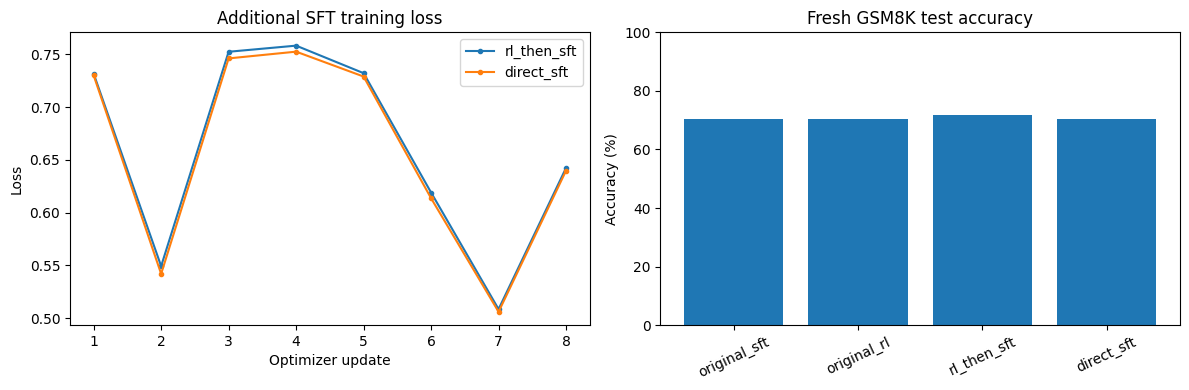

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for branch in ['rl_then_sft', 'direct_sft']:
    path = OUT/branch/'logs'/f'{branch}_metrics.jsonl'
    points = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    points = [r for r in points if r.get('event') == 'train_log' and 'loss' in r]
    if points:
        frame = pd.DataFrame(points).drop_duplicates('current', keep='last').sort_values('current')
        axes[0].plot(frame['current'], frame['loss'], marker='.', label=branch)
axes[0].set(title='Additional SFT training loss', xlabel='Optimizer update', ylabel='Loss')
axes[0].legend()
table = pd.read_csv(OUT/'comparison.csv')
axes[1].bar(table['stage'], table['accuracy_percent'])
axes[1].set(title='Fresh GSM8K test accuracy', ylabel='Accuracy (%)', ylim=(0, 100))
axes[1].tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUT/'comparison_plot.png', dpi=160)
plt.show()
